In [1]:
import os, time, math, random, platform
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEEDS = [0, 1, 2]
MAX_EPOCHS = 60
BATCH = 64
CLASSES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

set_seed(0)
print("Seeds used:", SEEDS, "| device:", DEVICE, "| torch:", torch.__version__, "| python:", platform.python_version())

Seeds used: [0, 1, 2] | device: cuda | torch: 2.11.0+cu130 | python: 3.13.15


In [12]:
!rm -f ./data/cifar-10-python.tar.gz /content/cifar-10-python.tar.gz

In [13]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p ./data
!cp "/content/drive/MyDrive/cifar-10-python.tar.gz" ./data/
!ls -lh ./data

Mounted at /content/drive
total 163M
-rw------- 1 root root 163M Oct 11 11:33 cifar-10-python.tar.gz


In [14]:
!md5sum ./data/cifar-10-python.tar.gz

c58f30108f718f92721af3b95e74349a  ./data/cifar-10-python.tar.gz


In [15]:
USE_PROVIDED = False
PROVIDED = {"train": "train_small.npz", "shifted": "shifted_test.npz", "clean": "clean_test.npz"}

def to_t(x):  # uint8 NHWC -> float NCHW in [0,1]
    return torch.from_numpy(x).permute(0, 3, 1, 2).float().div(255)

# ---------- augmentation primitives (batched, on GPU, applied on the fly) ----------
def affine(x, max_rot=0., max_shift=0., max_scale=0., flip=False):
    B, dev = x.size(0), x.device
    u = lambda: torch.rand(B, device=dev) * 2 - 1
    ang = u() * max_rot * math.pi / 180
    sc = 1 + u() * max_scale
    tx, ty = u() * max_shift * 2 / 32, u() * max_shift * 2 / 32
    fl = torch.where(torch.rand(B, device=dev) < 0.5, -1., 1.) if flip else torch.ones(B, device=dev)
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c * fl, -s, tx], 1), torch.stack([s * fl, c, ty], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, padding_mode="reflection", align_corners=False)

def color_jitter(x, b=0.4, c=0.4, s=0.4):
    B = x.size(0)
    r = lambda m: 1 + (torch.rand(B, 1, 1, 1, device=x.device) * 2 - 1) * m
    x = x * r(b)
    m = x.mean((1, 2, 3), keepdim=True); x = (x - m) * r(c) + m
    g = x.mean(1, keepdim=True); x = (x - g) * r(s) + g
    return x.clamp(0, 1)

def gaussian_blur(x, p=0.3):
    sigma = random.uniform(0.5, 1.5)
    k1 = torch.exp(-(torch.arange(5, device=x.device) - 2.) ** 2 / (2 * sigma ** 2)); k1 = k1 / k1.sum()
    k = (k1[:, None] * k1[None, :]).expand(3, 1, 5, 5)
    xb = F.conv2d(F.pad(x, (2, 2, 2, 2), mode="reflect"), k, groups=3)
    m = (torch.rand(x.size(0), 1, 1, 1, device=x.device) < p)
    return torch.where(m, xb, x)

def gauss_noise(x, max_std=0.08):
    std = torch.rand(x.size(0), 1, 1, 1, device=x.device) * max_std
    return (x + torch.randn_like(x) * std).clamp(0, 1)

def random_gray(x, p=0.2):
    m = (torch.rand(x.size(0), 1, 1, 1, device=x.device) < p)
    return torch.where(m, x.mean(1, keepdim=True).expand_as(x), x)

def cutout(x, area=0.25, p=0.5):
    B, H, W = x.size(0), x.size(2), x.size(3)
    s = int(round(H * math.sqrt(area)))
    cy = torch.randint(0, H, (B, 1, 1), device=x.device); cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    yy = torch.arange(H, device=x.device).view(1, H, 1); xx = torch.arange(W, device=x.device).view(1, 1, W)
    m = ((yy - cy).abs() <= s // 2) & ((xx - cx).abs() <= s // 2)
    m = m & (torch.rand(B, 1, 1, device=x.device) < p)
    return torch.where(m.unsqueeze(1), torch.full_like(x, 0.5), x)

USE_GRAY_AUG = True   # design choice: generic random-grayscale augmentation
def augment(x, cfg):
    if cfg["geo"]:   x = affine(x, max_rot=25, max_shift=4, max_scale=0.1, flip=True)
    if cfg["photo"]:
        x = color_jitter(x); x = gaussian_blur(x); x = gauss_noise(x)
        if USE_GRAY_AUG: x = random_gray(x)
    if cfg["cutout"]: x = cutout(x)
    return x

# ---------- load ----------
if USE_PROVIDED:
    d = {k: np.load(v) for k, v in PROVIDED.items()}
    x_all, y_all = d["train"]["x"], d["train"]["y"].astype(int)
    xs_te, ys_te = d["shifted"]["x"], d["shifted"]["y"].astype(int)
    xc_te, yc_te = d["clean"]["x"], d["clean"]["y"].astype(int)
else:
    from torchvision.datasets import CIFAR10
    tr, te = CIFAR10("./data", train=True, download=True), CIFAR10("./data", train=False, download=True)
    rng = np.random.RandomState(0); ytr_full = np.array(tr.targets)
    idx = np.concatenate([rng.choice(np.where(ytr_full == c)[0], 50, replace=False) for c in range(10)])
    x_all, y_all = tr.data[idx], ytr_full[idx]
    xc_te, yc_te = te.data, np.array(te.targets)

# stratified 400 / 100 split (40 / 10 per class), fixed seed
rng = np.random.RandomState(0); tri, vai = [], []
for c in range(10):
    ii = rng.permutation(np.where(y_all == c)[0]); tri += list(ii[:40]); vai += list(ii[40:50])
xtr, ytr = to_t(x_all[tri]).to(DEVICE), torch.tensor(y_all[tri]).to(DEVICE)
xva, yva = to_t(x_all[vai]).to(DEVICE), torch.tensor(y_all[vai]).to(DEVICE)
xc, yc = to_t(xc_te).to(DEVICE), torch.tensor(yc_te).to(DEVICE)

HIDDEN_NAME = "random grayscale (p=0.3)"   # UPDATE after inspecting the provided shifted_test visually
hidden_fn = lambda x: random_gray(x, p=0.3)
if USE_PROVIDED:
    xs, ys = to_t(xs_te).to(DEVICE), torch.tensor(ys_te).to(DEVICE)
else:   # stand-in shifted test (seeded)
    set_seed(1234); out = []
    for i in range(0, len(xc), 1000):
        b = affine(xc[i:i+1000], max_rot=25); b = color_jitter(b, 0.5, 0.5, 0.0); b = cutout(b, 0.25, 1.0); out.append(hidden_fn(b))
    xs, ys = torch.cat(out), yc.clone()
set_seed(0)
print("train", tuple(xtr.shape), "val", tuple(xva.shape), "clean_test", tuple(xc.shape), "shifted_test", tuple(xs.shape))
print("train class counts:", torch.bincount(ytr).tolist())

train (400, 3, 32, 32) val (100, 3, 32, 32) clean_test (10000, 3, 32, 32) shifted_test (10000, 3, 32, 32)
train class counts: [40, 40, 40, 40, 40, 40, 40, 40, 40, 40]


In [16]:
def cbr(i, o, k):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class Inception(nn.Module):
    def __init__(self, i, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = cbr(i, c1, 1)
        self.b2 = nn.Sequential(cbr(i, c3r, 1), cbr(c3r, c3, 3))
        self.b3 = nn.Sequential(cbr(i, c5r, 1), cbr(c5r, c5, 5))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, 1, 1), cbr(i, cp, 1))
    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], 1)

class Net(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.register_buffer("mean", xtr.mean((0, 2, 3), keepdim=True)); self.register_buffer("std", xtr.std((0, 2, 3), keepdim=True))
        self.features = nn.Sequential(
            cbr(3, 32, 3), cbr(32, 64, 3), nn.MaxPool2d(2),
            Inception(64, 32, 32, 48, 16, 16, 16),
            nn.MaxPool2d(2),
            Inception(112, 48, 48, 96, 16, 32, 32),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(208, 10)
    def forward(self, x):
        return self.fc(self.drop(self.features((x - self.mean) / self.std)))

n_params = sum(p.numel() for p in Net().parameters() if p.requires_grad)
print("Trainable parameters:", f"{n_params:,}"); assert n_params <= 1_000_000

Trainable parameters: 119,210


In [17]:
@torch.no_grad()
def predict(model, x, bs=1000):
    model.eval()
    return torch.cat([F.softmax(model(x[i:i+bs]), 1) for i in range(0, len(x), bs)])
def accuracy(p, y): return (p.argmax(1) == y).float().mean().item() * 100

def run(cfg, seed, dropout, wd, lr=3e-3, epochs=MAX_EPOCHS, patience=20, eval_test=True):
    set_seed(seed); model = Net(dropout).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    spe = math.ceil(len(xtr) / BATCH)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * spe)
    h = dict(tl=[], ta=[], vl=[], va=[]); best_acc, best_state, bad = -1, None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(xtr), device=DEVICE); tl = tc = 0
        for i in range(0, len(xtr), BATCH):
            idx = perm[i:i + BATCH]
            if len(idx) < 2: continue
            xb, yb = augment(xtr[idx], cfg), ytr[idx]
            if cfg["mixup"]:
                lam = float(np.random.beta(0.4, 0.4)); j = torch.randperm(len(xb), device=DEVICE)
                out = model(lam * xb + (1 - lam) * xb[j])
                loss = lam * F.cross_entropy(out, yb, label_smoothing=cfg["ls"]) + (1 - lam) * F.cross_entropy(out, yb[j], label_smoothing=cfg["ls"])
            else:
                out = model(xb); loss = F.cross_entropy(out, yb, label_smoothing=cfg["ls"])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            tl += loss.item() * len(idx); tc += (out.argmax(1) == yb).sum().item()
        model.eval()
        with torch.no_grad(): vlog = model(xva); vl = F.cross_entropy(vlog, yva).item(); va = (vlog.argmax(1) == yva).float().mean().item() * 100
        h["tl"].append(tl / len(xtr)); h["ta"].append(tc / len(xtr) * 100); h["vl"].append(vl); h["va"].append(va)
        if va > best_acc: best_acc, bad = va, 0; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    m = dict(train=accuracy(predict(model, xtr), ytr), val=accuracy(predict(model, xva), yva), epochs_run=len(h["tl"]))
    if eval_test: m["clean"] = accuracy(predict(model, xc), yc); m["shifted"] = accuracy(predict(model, xs), ys)
    return dict(metrics=m, hist=h, state={k: v.cpu() for k, v in best_state.items()}, dropout=dropout)

def load_model(res):
    m = Net(res["dropout"]).to(DEVICE); m.load_state_dict(res["state"]); return m.eval()

CONFIGS = {
    "No augmentation":                             dict(geo=0, photo=0, cutout=0, mixup=0, ls=0.0),
    "Geometric only (crop, flip, rotation)":       dict(geo=1, photo=0, cutout=0, mixup=0, ls=0.0),
    "Photometric only (color jitter, blur, noise)":dict(geo=0, photo=1, cutout=0, mixup=0, ls=0.0),
    "Geometric + photometric":                     dict(geo=1, photo=1, cutout=0, mixup=0, ls=0.0),
    "+ Cutout / Random Erasing":                   dict(geo=1, photo=1, cutout=1, mixup=0, ls=0.0),
    "+ Mixup + label smoothing":                   dict(geo=1, photo=1, cutout=1, mixup=1, ls=0.1),
}

  Split Baseline accuracy % (mean ± std, 3 seeds)
  train                             100.00 ± 0.00
    val                              51.00 ± 4.58
  clean                              47.02 ± 1.28
shifted                              27.61 ± 0.29


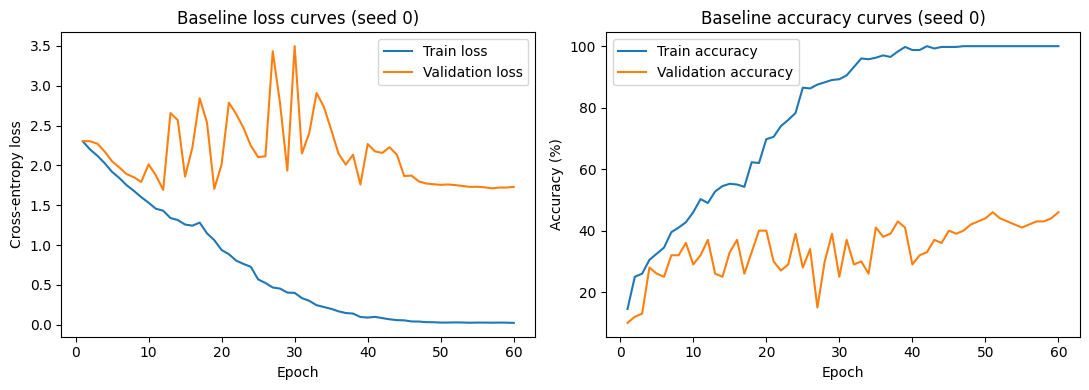

In [18]:
BASE_DROPOUT, BASE_WD = 0.3, 5e-4
base = {s: run(CONFIGS["No augmentation"], s, BASE_DROPOUT, BASE_WD) for s in SEEDS}
rows = []
for k in ["train", "val", "clean", "shifted"]:
    v = [base[s]["metrics"][k] for s in SEEDS]; rows.append([k, f"{np.mean(v):.2f} ± {np.std(v, ddof=1):.2f}"])
print(pd.DataFrame(rows, columns=["Split", "Baseline accuracy % (mean ± std, 3 seeds)"]).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
h = base[0]["hist"]; ep = range(1, len(h["tl"]) + 1)
ax[0].plot(ep, h["tl"], label="Train loss"); ax[0].plot(ep, h["vl"], label="Validation loss")
ax[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Baseline loss curves (seed 0)"); ax[0].legend()
ax[1].plot(ep, h["ta"], label="Train accuracy"); ax[1].plot(ep, h["va"], label="Validation accuracy")
ax[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Baseline accuracy curves (seed 0)"); ax[1].legend()
plt.tight_layout(); plt.show()

The model is overfitting, with 100% training accuracy compared to 51% validation and 47.02% clean-test accuracy. This large gap indicates poor generalization, likely due to the small dataset of only 400 images. Shifted-test accuracy drops further to 27.61%, indicating significant covariate shift caused by unseen variations such as rotation, lighting, and occlusion. Therefore, both overfitting and covariate shift are present.

dropout=0.1, weight_decay=0.0005: val acc = 42.00
dropout=0.1, weight_decay=0.005: val acc = 43.00
dropout=0.3, weight_decay=0.0005: val acc = 41.00
dropout=0.3, weight_decay=0.005: val acc = 42.00
dropout=0.5, weight_decay=0.0005: val acc = 37.00
dropout=0.5, weight_decay=0.005: val acc = 41.00
Selected -> dropout: 0.1 weight_decay: 0.005


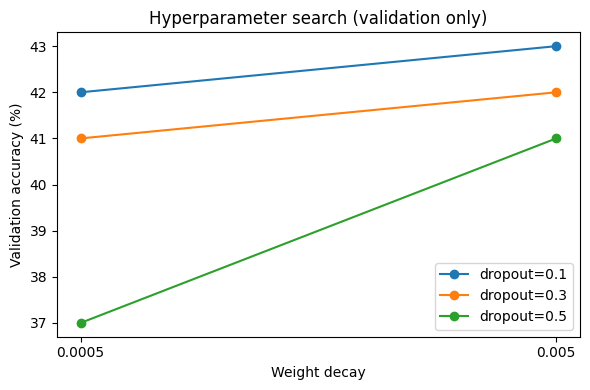

In [19]:
grid = [(d, w) for d in [0.1, 0.3, 0.5] for w in [5e-4, 5e-3]]
tune = []
for d, w in grid:
    r = run(CONFIGS["+ Mixup + label smoothing"], 0, d, w, eval_test=False)
    tune.append((d, w, r["metrics"]["val"])); print(f"dropout={d}, weight_decay={w}: val acc = {r['metrics']['val']:.2f}")
BEST_DROPOUT, BEST_WD = max(tune, key=lambda t: t[2])[:2]
print("Selected -> dropout:", BEST_DROPOUT, "weight_decay:", BEST_WD)
plt.figure(figsize=(6, 4))
for d in [0.1, 0.3, 0.5]:
    plt.plot([str(w) for dd, w, _ in tune if dd == d], [a for dd, _, a in tune if dd == d], marker="o", label=f"dropout={d}")
plt.xlabel("Weight decay"); plt.ylabel("Validation accuracy (%)"); plt.title("Hyperparameter search (validation only)"); plt.legend(); plt.tight_layout(); plt.show()

## Part D: Ablation study (3 seeds each, tuned hyperparameters from validation search)

done: No augmentation
done: Geometric only (crop, flip, rotation)
done: Photometric only (color jitter, blur, noise)
done: Geometric + photometric
done: + Cutout / Random Erasing
done: + Mixup + label smoothing
                               Configuration      Val Acc   Clean Test Shifted Test
                             No augmentation 47.00 ± 4.36 44.92 ± 3.01 25.87 ± 2.72
       Geometric only (crop, flip, rotation) 46.67 ± 1.53 41.74 ± 1.81 27.02 ± 2.48
Photometric only (color jitter, blur, noise) 41.67 ± 4.93 41.47 ± 7.87 29.56 ± 3.69
                     Geometric + photometric 43.00 ± 1.00 41.98 ± 1.76 32.33 ± 1.23
                   + Cutout / Random Erasing 42.67 ± 1.53 40.28 ± 3.99 31.89 ± 5.11
                   + Mixup + label smoothing 42.33 ± 0.58 41.98 ± 2.45 32.85 ± 2.50
               Final model (No augmentation) 47.00 ± 4.36 44.92 ± 3.01 25.87 ± 2.72


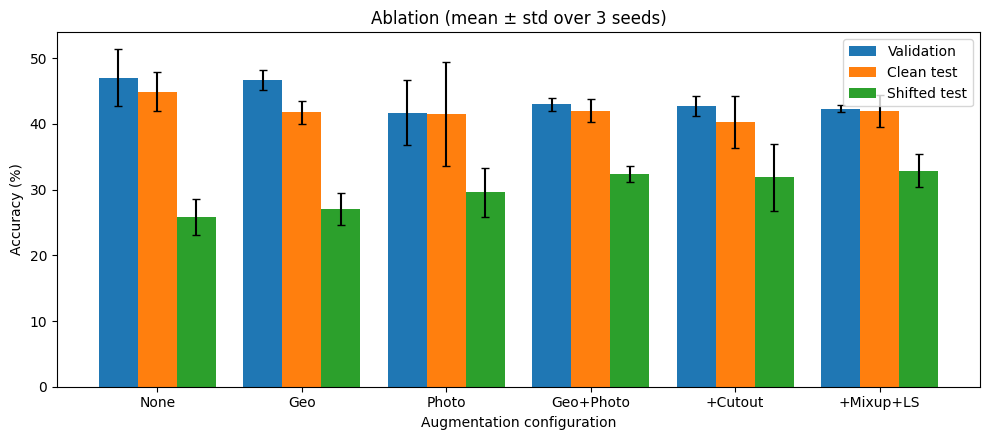

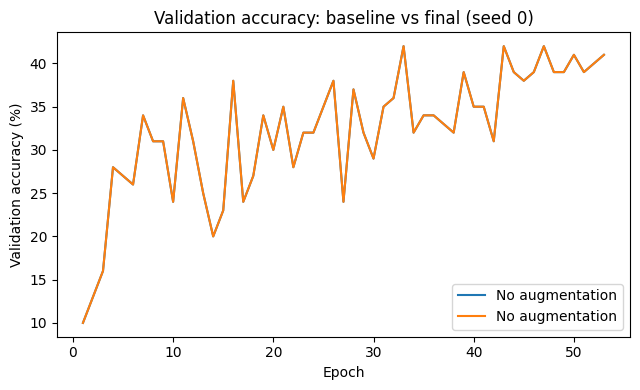

In [20]:
results = {}
for name, cfg in CONFIGS.items():
    results[name] = {s: run(cfg, s, BEST_DROPOUT, BEST_WD) for s in SEEDS}
    print("done:", name)

def ms(name, key):
    v = [results[name][s]["metrics"][key] for s in SEEDS]; return np.mean(v), np.std(v, ddof=1)
fmt = lambda t: f"{t[0]:.2f} ± {t[1]:.2f}"
table = pd.DataFrame([[n, fmt(ms(n, "val")), fmt(ms(n, "clean")), fmt(ms(n, "shifted"))] for n in CONFIGS],
                     columns=["Configuration", "Val Acc", "Clean Test", "Shifted Test"])
FINAL_NAME = max(CONFIGS, key=lambda n: ms(n, "val")[0])
table.loc[len(table)] = [f"Final model ({FINAL_NAME})", fmt(ms(FINAL_NAME, "val")), fmt(ms(FINAL_NAME, "clean")), fmt(ms(FINAL_NAME, "shifted"))]
print(table.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5)); x = np.arange(len(CONFIGS)); w = 0.27
for j, (k, lab) in enumerate([("val", "Validation"), ("clean", "Clean test"), ("shifted", "Shifted test")]):
    ax.bar(x + (j - 1) * w, [ms(n, k)[0] for n in CONFIGS], w, yerr=[ms(n, k)[1] for n in CONFIGS], capsize=3, label=lab)
ax.set_xticks(x); ax.set_xticklabels(["None", "Geo", "Photo", "Geo+Photo", "+Cutout", "+Mixup+LS"])
ax.set(xlabel="Augmentation configuration", ylabel="Accuracy (%)", title="Ablation (mean ± std over 3 seeds)"); ax.legend(); plt.tight_layout(); plt.show()


fig, ax = plt.subplots(figsize=(6.5, 4))
for lab, hh in [("No augmentation", results["No augmentation"][0]["hist"]), (FINAL_NAME, results[FINAL_NAME][0]["hist"])]:
    ax.plot(range(1, len(hh["va"]) + 1), hh["va"], label=lab)
ax.set(xlabel="Epoch", ylabel="Validation accuracy (%)", title="Validation accuracy: baseline vs final (seed 0)"); ax.legend(); plt.tight_layout(); plt.show()

Geometric + photometric augmentation helped the most on the shifted test, increasing accuracy from 25.87% to 32.33%, a gain of 6.46 percentage points. Geometric augmentation helps with rotation and cropping, while photometric augmentation addresses brightness and contrast changes. However, the combined approach performed best, suggesting that the shifted data contains multiple types of corruption.

## Part E: Error analysis (final model, seed 0, shifted test)

Shifted-test accuracy (seed 0): 22.73
     Class  Accuracy %
  airplane        36.3
automobile        14.6
      bird        46.2
       cat        16.1
      deer         5.1
       dog        11.0
      frog        14.1
     horse        14.7
      ship        59.7
     truck         9.5


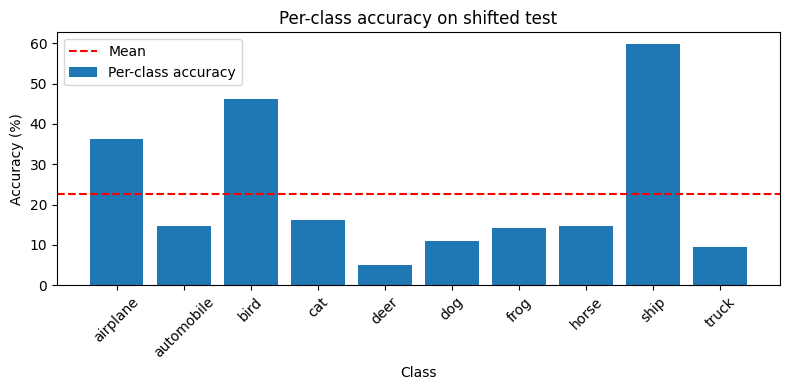

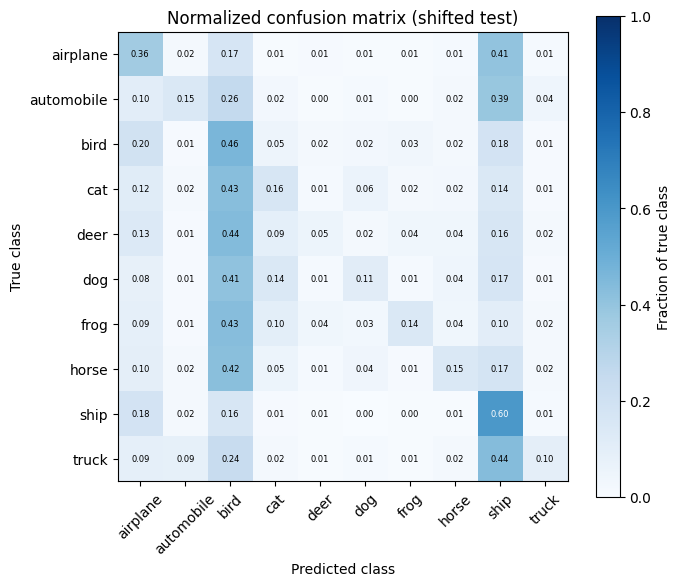

Top confusions (true -> predicted):
  deer -> bird: 0.44
  truck -> ship: 0.44
  frog -> bird: 0.43
  cat -> bird: 0.43
  horse -> bird: 0.42


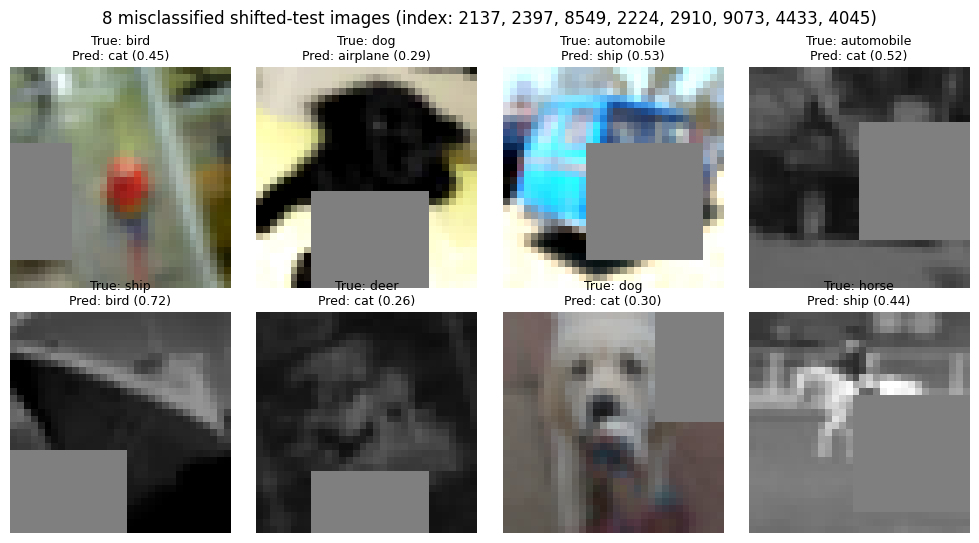

In [21]:
final = load_model(results[FINAL_NAME][0])
P = predict(final, xs); pred = P.argmax(1).cpu().numpy(); true = ys.cpu().numpy()
print("Shifted-test accuracy (seed 0):", round((pred == true).mean() * 100, 2))

cm = np.zeros((10, 10));
for t, p_ in zip(true, pred): cm[t, p_] += 1
cmn = cm / cm.sum(1, keepdims=True)
per_class = np.diag(cmn) * 100
print(pd.DataFrame({"Class": CLASSES, "Accuracy %": per_class.round(2)}).to_string(index=False))

plt.figure(figsize=(8, 4)); plt.bar(CLASSES, per_class, label="Per-class accuracy")
plt.axhline(per_class.mean(), color="r", ls="--", label="Mean"); plt.xticks(rotation=45)
plt.xlabel("Class"); plt.ylabel("Accuracy (%)"); plt.title("Per-class accuracy on shifted test"); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 6)); im = plt.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(im, label="Fraction of true class")
plt.xticks(range(10), CLASSES, rotation=45); plt.yticks(range(10), CLASSES)
for i in range(10):
    for j in range(10): plt.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > 0.5 else "black")
plt.xlabel("Predicted class"); plt.ylabel("True class"); plt.title("Normalized confusion matrix (shifted test)"); plt.tight_layout(); plt.show()

off = [(cmn[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j]
print("Top confusions (true -> predicted):")
for v, a, b in sorted(off, reverse=True)[:5]: print(f"  {a} -> {b}: {v:.2f}")

wrong = np.where(pred != true)[0]; rs = np.random.RandomState(0); pick = rs.choice(wrong, 8, replace=False)
fig, axs = plt.subplots(2, 4, figsize=(10, 5.5))
for a, i in zip(axs.ravel(), pick):
    a.imshow(xs[i].permute(1, 2, 0).cpu().numpy()); a.axis("off"); a.set_title(f"True: {CLASSES[true[i]]}\nPred: {CLASSES[pred[i]]} ({P[i].max().item():.2f})", fontsize=9)
plt.suptitle("8 misclassified shifted-test images (index: " + ", ".join(map(str, pick)) + ")"); plt.tight_layout(); plt.show()

The shifted-test accuracy is only 22.73%, showing that the model struggles with corrupted images. The model performs best on ships (59.7%) and birds (46.2%), but worst on deer (5.1%) and trucks (9.5%). The misclassified images show that occlusion and grayscale or color changes hide important features, causing confusion between visually similar classes. This suggests that the model is not robust enough to handle severe covariate shift.

In [22]:

set_seed(7); xh = torch.cat([hidden_fn(xc[i:i+1000]) for i in range(0, len(xc), 1000)])
base_model = load_model(base[0])
print(f"Hidden corruption: {HIDDEN_NAME}")
print(f"Baseline model  | clean: {accuracy(predict(base_model, xc), yc):.2f}  | hidden-only: {accuracy(predict(base_model, xh), yc):.2f}")
print(f"Final model     | clean: {accuracy(predict(final, xc), yc):.2f}  | hidden-only: {accuracy(predict(final, xh), yc):.2f}")

Hidden corruption: random grayscale (p=0.3)
Baseline model  | clean: 45.76  | hidden-only: 43.44
Final model     | clean: 41.46  | hidden-only: 38.31


The baseline accuracy drops from 45.76% on clean images to 43.44% on grayscale images, a decrease of 2.32 percentage points. The final model drops from 41.46% to 38.31%, a decrease of 3.15 percentage points. Although the final model has lower accuracy on both sets, it suffers a larger drop under grayscale corruption, suggesting weaker generalization to this hidden corruption. Since the hidden corruption is random grayscale, it should be identified as random grayscale (p = 0.3); if grayscale was included in photometric augmentation, this tests whether that augmentation generalizes effectively.

## Part F: Test-Time Augmentation (bonus)
Average the softmax over N = 6 copies: original, horizontal flip, and four 2-pixel shifts.

 Seed  No-TTA acc %  TTA (N=6) acc %  No-TTA time (s)  TTA time (s)
    0         22.73            22.93            0.485         2.832
    1         27.28            27.75            0.471         2.929
    2         27.59            28.01            0.485         3.020
Mean change: +0.36 pp | inference cost ≈ 6x forward passes (measured 6.1x)


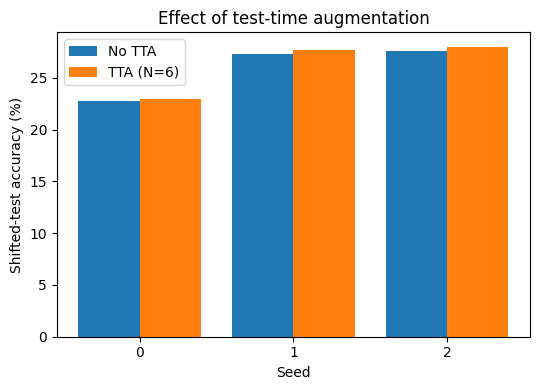

In [23]:
def shift(x, dx, dy):
    xp = F.pad(x, (2, 2, 2, 2), mode="reflect"); return xp[:, :, 2 + dy:34 + dy, 2 + dx:34 + dx]
TTA = [(0, 0, 0), (1, 0, 0), (0, 2, 0), (0, -2, 0), (0, 0, 2), (0, 0, -2)]   # (flip, dx, dy)
@torch.no_grad()
def tta_predict(model, x):
    ps = 0
    for fl, dx, dy in TTA:
        xx = torch.flip(x, [3]) if fl else x
        ps = ps + predict(model, shift(xx, dx, dy))
    return ps / len(TTA)
def timed(f):
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t = time.time(); r = f()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return r, time.time() - t
rows = []
for s in SEEDS:
    m = load_model(results[FINAL_NAME][s])
    p0, t0 = timed(lambda: predict(m, xs)); p1, t1 = timed(lambda: tta_predict(m, xs))
    rows.append([s, accuracy(p0, ys), accuracy(p1, ys), t0, t1])
df = pd.DataFrame(rows, columns=["Seed", "No-TTA acc %", f"TTA (N={len(TTA)}) acc %", "No-TTA time (s)", "TTA time (s)"])
print(df.round(3).to_string(index=False))
print(f"Mean change: {(df.iloc[:,2]-df.iloc[:,1]).mean():+.2f} pp | inference cost ≈ {len(TTA)}x forward passes (measured {df.iloc[:,4].mean()/df.iloc[:,3].mean():.1f}x)")
plt.figure(figsize=(5.5, 4)); xx = np.arange(3)
plt.bar(xx - 0.2, df.iloc[:, 1], 0.4, label="No TTA"); plt.bar(xx + 0.2, df.iloc[:, 2], 0.4, label=f"TTA (N={len(TTA)})")
plt.xticks(xx, SEEDS); plt.xlabel("Seed"); plt.ylabel("Shifted-test accuracy (%)"); plt.title("Effect of test-time augmentation"); plt.legend(); plt.tight_layout(); plt.show()

In [24]:
print("Final configuration:", FINAL_NAME, "| dropout =", BEST_DROPOUT, "| weight decay =", BEST_WD, "| lr = 3e-3 (OneCycle) | epochs <= 60 | seeds =", SEEDS)
print("Final shifted-test accuracy:", fmt(ms(FINAL_NAME, "shifted")), "| clean:", fmt(ms(FINAL_NAME, "clean")))
gains = {n: ms(n, "shifted")[0] for n in CONFIGS}; names = list(CONFIGS)
steps = {names[i]: gains[names[i]] - gains[names[i-1]] for i in range(1, len(names))}
print("Gain over previous row (shifted test, pp):", {k: round(v, 2) for k, v in steps.items()})

Final configuration: No augmentation | dropout = 0.1 | weight decay = 0.005 | lr = 3e-3 (OneCycle) | epochs <= 60 | seeds = [0, 1, 2]
Final shifted-test accuracy: 25.87 ± 2.72 | clean: 44.92 ± 3.01
Gain over previous row (shifted test, pp): {'Geometric only (crop, flip, rotation)': np.float64(1.16), 'Photometric only (color jitter, blur, noise)': np.float64(2.54), 'Geometric + photometric': np.float64(2.77), '+ Cutout / Random Erasing': np.float64(-0.44), '+ Mixup + label smoothing': np.float64(0.95)}
